In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/titanic.csv")

# display first 5 records
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-

In [3]:
df.describe(include="all")

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2. Data Quality Assessment

In this section, we examine:
- Missing values
- Duplicate records
- Target variable distribution
- Numerical and categorical features

In [4]:
# Calculate missing values
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_values

,Missing Count,Missing Percentage
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


In [5]:
# Count duplicate records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 107


survived
0    549
1    342
Name: count, dtype: int64


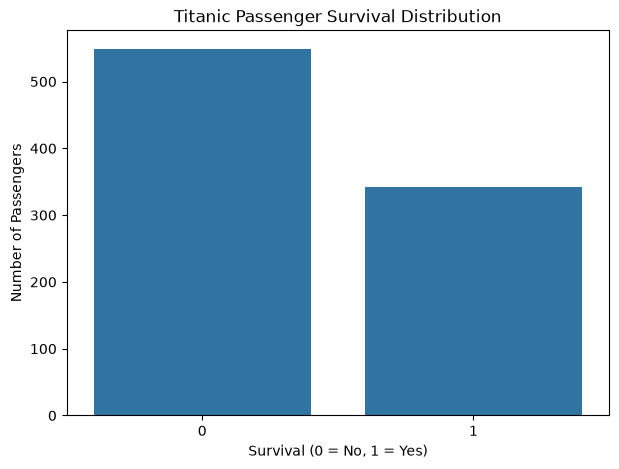

In [6]:
# Count survival outcomes
survival_counts = df["survived"].value_counts()

print(survival_counts)

# Visualize survival distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

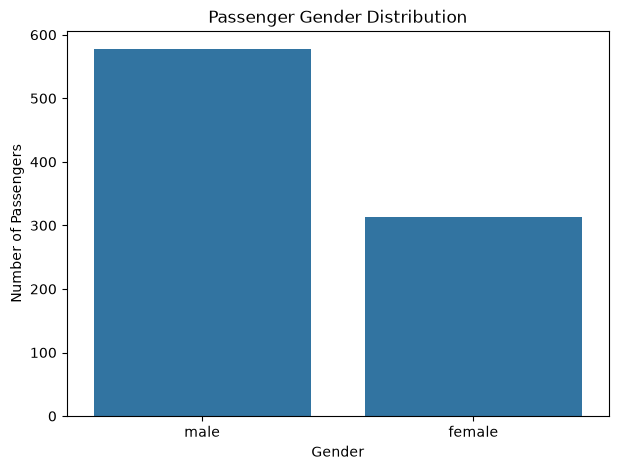

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex")

plt.title("Passenger Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

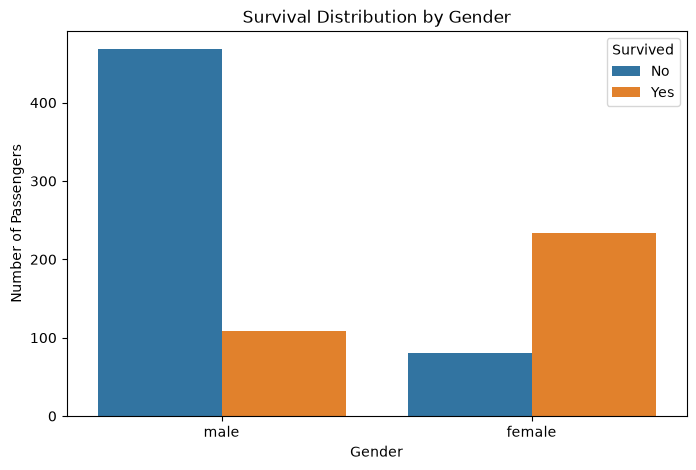

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sex",
    hue="survived"
)

plt.title("Survival Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survived",
    labels=["No", "Yes"]
)

plt.show()

# 3. Exploratory Data Analysis (EDA)

The objective of this section is to identify relationships
between passenger characteristics and survival outcomes.

We will investigate:

1. Survival rate by gender
2. Survival rate by passenger class
3. Survival rate by age
4. Survival rate by ticket fare
5. Survival rate by family size
6. Correlations between numerical features

In [9]:
gender_survival = df.groupby("sex")["survived"].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival)

Survival Rate by Gender:
sex
female    74.203822
male      18.890815
Name: survived, dtype: float64


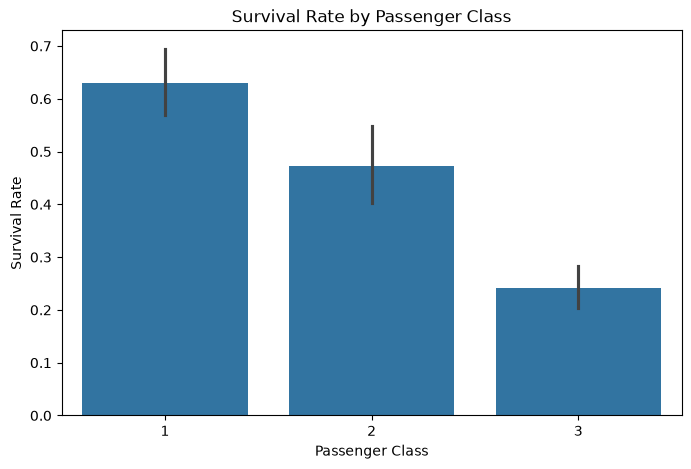

In [10]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="pclass",
    y="survived"
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

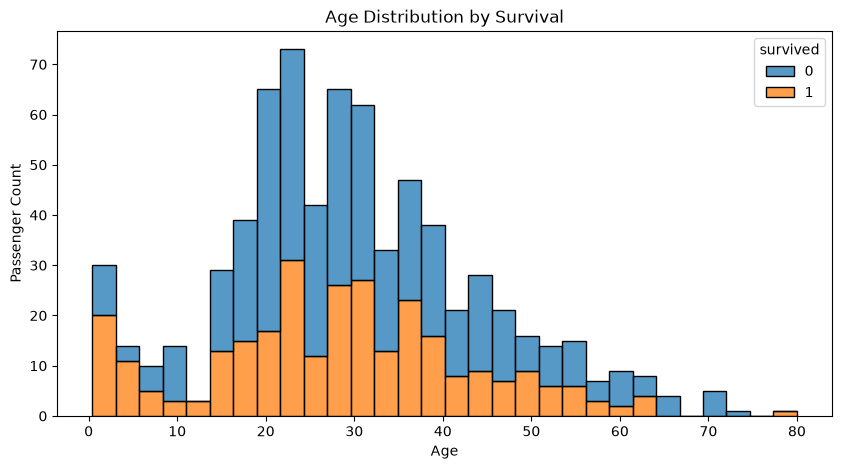

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    hue="survived",
    bins=30,
    multiple="stack"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Passenger Count")

plt.show()

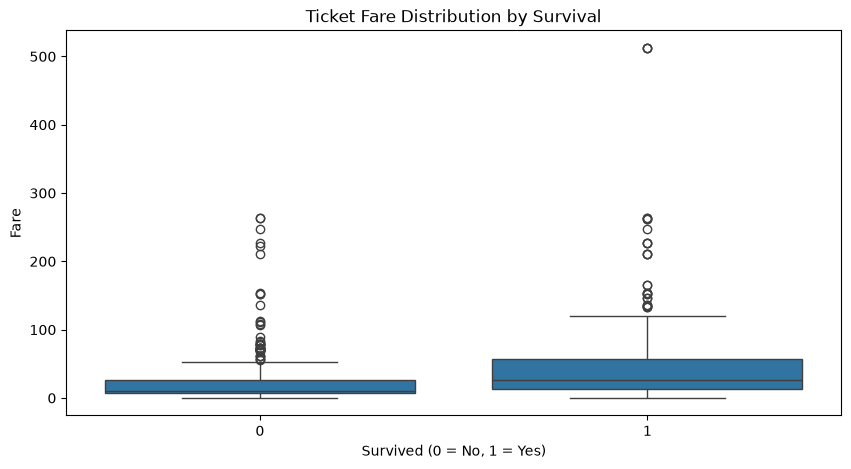

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="survived",
    y="fare"
)

plt.title("Ticket Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")

plt.show()

In [13]:
df["family_size"] = df["sibsp"] + df["parch"] + 1

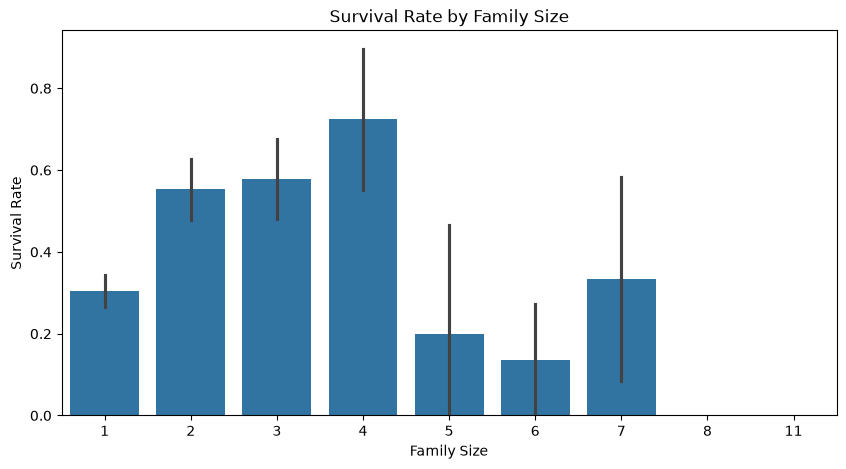

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="family_size",
    y="survived"
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

In [15]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Total duplicate-related records:", len(duplicate_rows))

duplicate_rows.head(10)

Total duplicate-related records: 160


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,family_size
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True,1
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True,1
29,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True,1
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True,1
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1
42,0,3,male,NaN,0,0,7.8958,C,Third,man,True,NaN,Cherbourg,no,True,1
45,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1
46,0,3,male,NaN,1,0,15.5000,Q,Third,man,True,NaN,Queenstown,no,False,2
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True,1


In [16]:
class_gender_survival = df.pivot_table(
    index="pclass",
    columns="sex",
    values="survived",
    aggfunc="mean"
) * 100

class_gender_survival

sex,female,male
pclass,,
1,96.808511,36.885246
2,92.105263,15.740741
3,50.000000,13.544669


In [17]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

age_survival = df.groupby(
    "age_group",
    observed=False
)["survived"].mean() * 100

age_survival

age_group
Child          57.971014
Teenager       42.857143
Young Adult    38.268156
Adult          40.000000
Senior         22.727273
Name: survived, dtype: float64

In [18]:
family_analysis = df.groupby("family_size").agg(
    Passenger_Count=("survived", "count"),
    Survival_Rate=("survived", "mean")
)

family_analysis["Survival_Rate"] *= 100

family_analysis

,Passenger_Count,Survival_Rate
family_size,,
1,537,30.353818
2,161,55.279503
3,102,57.843137
4,29,72.413793
5,15,20.000000
6,22,13.636364
7,12,33.333333
8,6,0.000000
11,7,0.000000


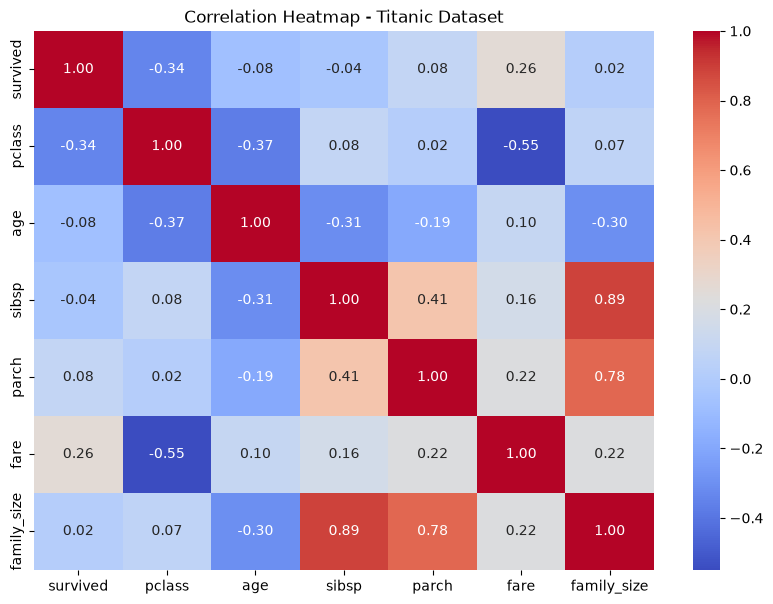

In [19]:
numerical_df = df.select_dtypes(include=["number"])

correlation = numerical_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Titanic Dataset")

plt.show()

## 3.6 EDA Findings and Observations

1. Female passengers had a substantially higher survival rate (74.20%)
   compared to male passengers (18.89%).

2. First-class passengers had the highest survival rate,
   while third-class passengers had the lowest.

3. Children had a higher survival rate than most other age groups.

4. Survivors generally paid higher ticket fares.

5. Passengers travelling with small families generally
   demonstrated better survival rates.

6. Passenger class showed a moderate negative correlation
   with survival (-0.34).

7. Fare showed a positive correlation with survival (+0.26).

8. Gender, passenger class, age and fare appear to be
   useful predictive features.

These observations will guide our feature selection
and model development.

# 4. Data Preprocessing

## 4.1 Feature Selection

Selecting relevant features and removing redundant
or potentially misleading columns.

In [20]:
# Create modelling dataset
model_df = df[
    [
        "survived",
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked",
        "family_size"
    ]
].copy()

# Display dataset
model_df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,family_size
0,0,3,male,22.0,1,0,7.2500,S,2
1,1,1,female,38.0,1,0,71.2833,C,2
2,1,3,female,26.0,0,0,7.9250,S,1
3,1,1,female,35.0,1,0,53.1000,S,2
4,0,3,male,35.0,0,0,8.0500,S,1


In [23]:
print("Original Dataset Shape:", df.shape)
print("Modelling Dataset Shape:", model_df.shape)

Original Dataset Shape: (891, 17)
Modelling Dataset Shape: (891, 9)


In [24]:
# Separate independent and dependent variables

X = model_df.drop("survived", axis=1)

y = model_df["survived"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 8)
Target Shape: (891,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Features: (712, 8)
Testing Features: (179, 8)

Training Target Distribution:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Testing Target Distribution:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [26]:
# Baseline feature selection

X = model_df[
    [
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked"
    ]
].copy()

y = model_df["survived"].copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (891, 7)
Target: (891,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (712, 7)
Testing: (179, 7)


In [28]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [29]:
numerical_features = [
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "pclass",
    "sex",
    "embarked"
]

In [30]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [31]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [33]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)

print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (712, 12)
Processed Testing Shape: (179, 12)


# 6. Model Development

We will train and compare three classification algorithms:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The objective is to identify the model that provides
the best predictive performance on unseen data.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [35]:
# Logistic Regression
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Decision Tree
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Random Forest
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

In [36]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

for name, model in models.items():

    model.fit(X_train, y_train)

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [37]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.804469,0.765625,0.710145,0.736842
0,Logistic Regression,0.804469,0.793103,0.666667,0.724409
2,Random Forest,0.793296,0.766667,0.666667,0.713178


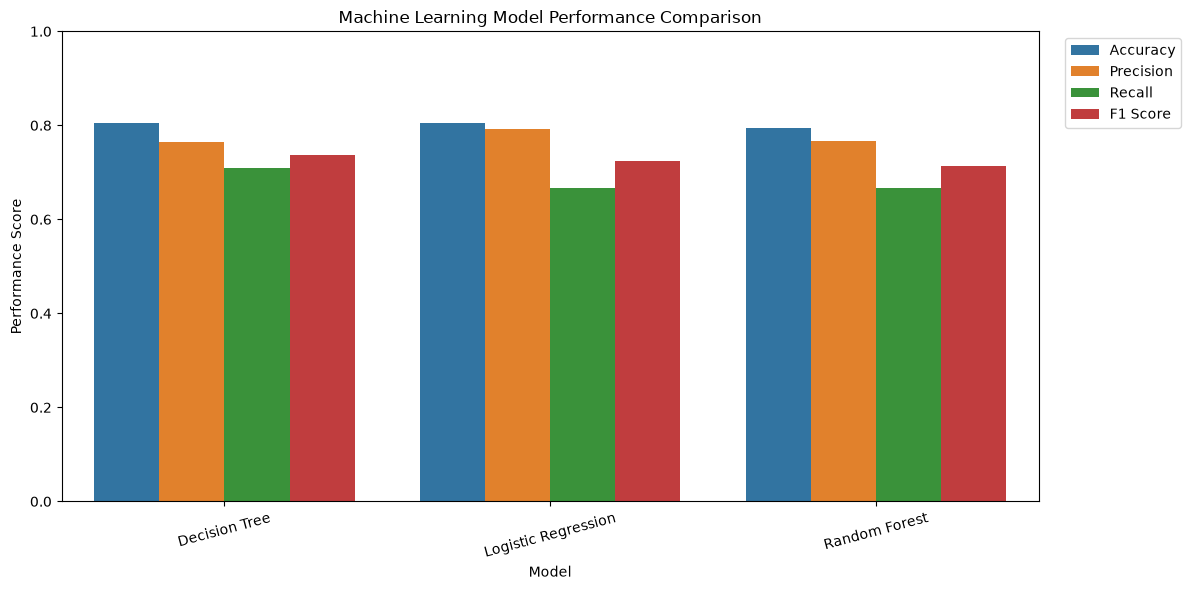

In [38]:
results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Performance Score")
plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# 7. Model Evaluation

In this section, we evaluate the classification models
using confusion matrices and classification reports.

The objective is to understand the prediction errors
and compare model performance.


Logistic Regression
[[98 12]
 [23 46]]


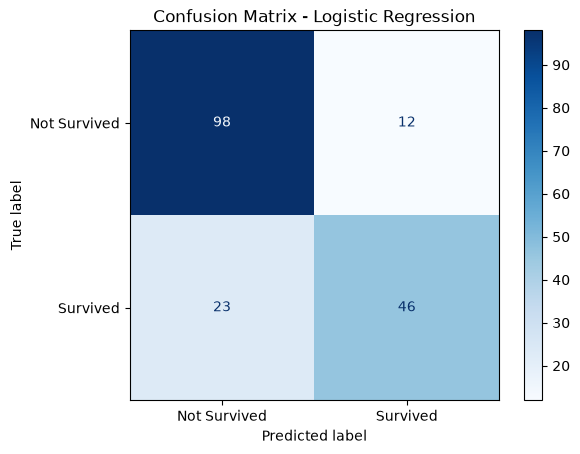


Decision Tree
[[95 15]
 [20 49]]


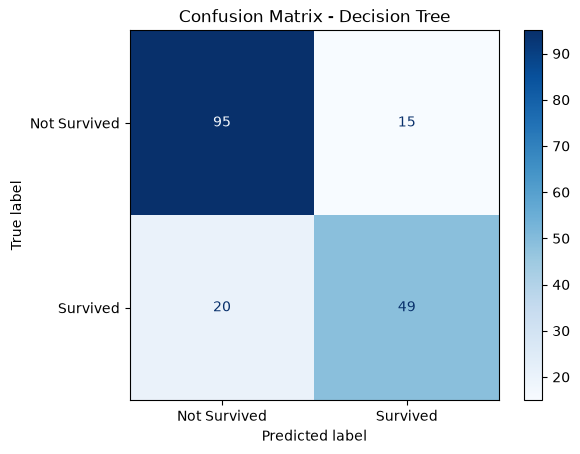


Random Forest
[[96 14]
 [23 46]]


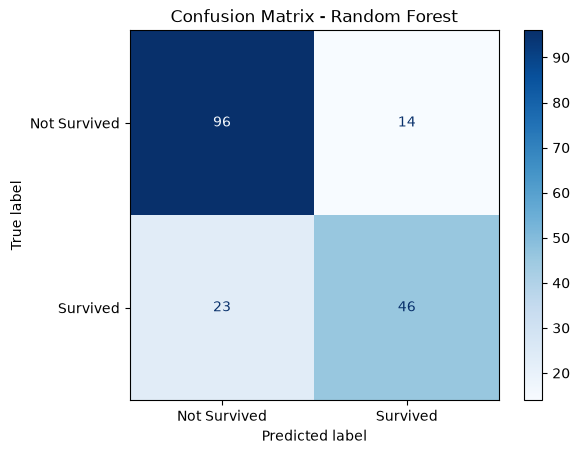

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():

    print(f"\n{name}")

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Survived", "Survived"]
    ).plot(cmap="Blues")

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

In [40]:
for name, model in models.items():

    print(f"\n{'='*50}")
    print(name)
    print('='*50)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Not Survived", "Survived"]
        )
    )


Logistic Regression
              precision    recall  f1-score   support

Not Survived       0.81      0.89      0.85       110
    Survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Decision Tree
              precision    recall  f1-score   support

Not Survived       0.83      0.86      0.84       110
    Survived       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179


Random Forest
              precision    recall  f1-score   support

Not Survived       0.81      0.87      0.84       110
    Survived       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79

In [41]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results)

cv_df.sort_values(
    by="Mean F1",
    ascending=False
)

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1
0,Logistic Regression,0.801980,0.765200,0.699731,0.730108
2,Random Forest,0.797745,0.750852,0.710572,0.729412
1,Decision Tree,0.769704,0.705668,0.689024,0.695863


# 8. Hyperparameter Tuning

Hyperparameter tuning is performed to identify
better model configurations.

RandomizedSearchCV is used to explore different
hyperparameter combinations using cross-validation.

In [42]:
from sklearn.model_selection import RandomizedSearchCV

In [43]:
lr_parameters = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

lr_search = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=lr_parameters,
    n_iter=10,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

lr_search.fit(X_train, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best CV F1 Score:", lr_search.best_score_)

Best Parameters: {'classifier__class_weight': 'balanced', 'classifier__C': 1}
Best CV F1 Score: 0.7304881511067981


In [44]:
dt_parameters = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 4, 8],
    "classifier__class_weight": [None, "balanced"]
}

dt_search = RandomizedSearchCV(
    estimator=decision_tree_model,
    param_distributions=dt_parameters,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

dt_search.fit(X_train, y_train)

print("Best Parameters:", dt_search.best_params_)
print("Best CV F1 Score:", dt_search.best_score_)

Best Parameters: {'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}
Best CV F1 Score: 0.7447984202377828


In [45]:
rf_parameters = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [None, 5, 8, 10, 15],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [None, "balanced"]
}

rf_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_parameters,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best CV F1 Score:", rf_search.best_score_)

Best Parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 15, 'classifier__class_weight': 'balanced'}
Best CV F1 Score: 0.7714708286424365


In [46]:
tuned_models = {
    "Tuned Logistic Regression": lr_search.best_estimator_,
    "Tuned Decision Tree": dt_search.best_estimator_,
    "Tuned Random Forest": rf_search.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Logistic Regression,0.810056,0.739726,0.782609,0.760563
2,Tuned Random Forest,0.798883,0.746269,0.724638,0.735294
1,Tuned Decision Tree,0.776536,0.737705,0.652174,0.692308


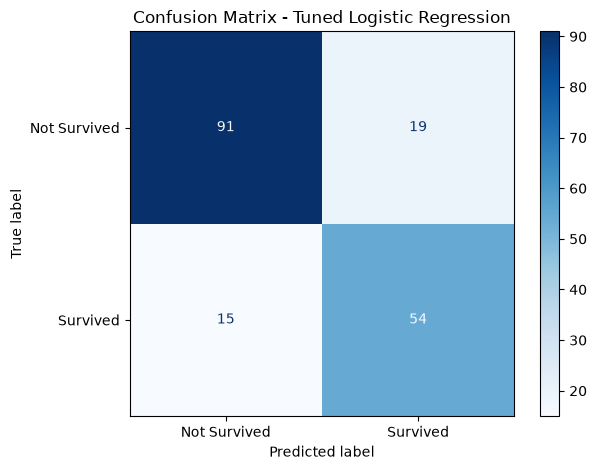

In [60]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

final_model = lr_search.best_estimator_

ConfusionMatrixDisplay.from_estimator(
    final_model,
    X_test,
    y_test,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.tight_layout()

plt.savefig(
    "../images/12_tuned_confusion_matrix_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Feature Engineering Experiments

In this section, we create additional features
to investigate whether engineered variables
improve model performance.

In [47]:
# Create experimental dataset

engineered_df = df[
    [
        "survived",
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked"
    ]
].copy()

# Family size
engineered_df["family_size"] = (
    engineered_df["sibsp"] +
    engineered_df["parch"] + 1
)

# Whether passenger travelled alone
engineered_df["is_alone"] = (
    engineered_df["family_size"] == 1
).astype(int)

# Fare per person
engineered_df["fare_per_person"] = (
    engineered_df["fare"] /
    engineered_df["family_size"]
)

# Age groups
engineered_df["age_group"] = pd.cut(
    engineered_df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=[
        "Child",
        "Teenager",
        "Young Adult",
        "Adult",
        "Senior"
    ]
)

engineered_df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,family_size,is_alone,fare_per_person,age_group
0,0,3,male,22.0,1,0,7.2500,S,2,0,3.62500,Young Adult
1,1,1,female,38.0,1,0,71.2833,C,2,0,35.64165,Adult
2,1,3,female,26.0,0,0,7.9250,S,1,1,7.92500,Young Adult
3,1,1,female,35.0,1,0,53.1000,S,2,0,26.55000,Young Adult
4,0,3,male,35.0,0,0,8.0500,S,1,1,8.05000,Young Adult


In [48]:
engineered_df[
    [
        "age",
        "sibsp",
        "parch",
        "family_size",
        "is_alone",
        "fare",
        "fare_per_person",
        "age_group"
    ]
].head(10)

,age,sibsp,parch,family_size,is_alone,fare,fare_per_person,age_group
0,22.0,1,0,2,0,7.2500,3.62500,Young Adult
1,38.0,1,0,2,0,71.2833,35.64165,Adult
2,26.0,0,0,1,1,7.9250,7.92500,Young Adult
3,35.0,1,0,2,0,53.1000,26.55000,Young Adult
4,35.0,0,0,1,1,8.0500,8.05000,Young Adult
5,NaN,0,0,1,1,8.4583,8.45830,NaN
6,54.0,0,0,1,1,51.8625,51.86250,Adult
7,2.0,3,1,5,0,21.0750,4.21500,Child
8,27.0,0,2,3,0,11.1333,3.71110,Young Adult
9,14.0,1,0,2,0,30.0708,15.03540,Teenager


In [49]:
engineered_df[
    [
        "age",
        "sibsp",
        "parch",
        "family_size",
        "is_alone",
        "fare",
        "fare_per_person",
        "age_group"
    ]
].head(10)

,age,sibsp,parch,family_size,is_alone,fare,fare_per_person,age_group
0,22.0,1,0,2,0,7.2500,3.62500,Young Adult
1,38.0,1,0,2,0,71.2833,35.64165,Adult
2,26.0,0,0,1,1,7.9250,7.92500,Young Adult
3,35.0,1,0,2,0,53.1000,26.55000,Young Adult
4,35.0,0,0,1,1,8.0500,8.05000,Young Adult
5,NaN,0,0,1,1,8.4583,8.45830,NaN
6,54.0,0,0,1,1,51.8625,51.86250,Adult
7,2.0,3,1,5,0,21.0750,4.21500,Child
8,27.0,0,2,3,0,11.1333,3.71110,Young Adult
9,14.0,1,0,2,0,30.0708,15.03540,Teenager


In [53]:
X_engineered = engineered_df.drop(
    "survived",
    axis=1
)

y_engineered = engineered_df["survived"]

X_train_eng, X_test_eng, y_train_eng, y_test_eng = (
    train_test_split(
        X_engineered,
        y_engineered,
        test_size=0.20,
        random_state=42,
        stratify=y_engineered
    )
)

In [50]:
engineered_numerical = [
    "age",
    "sibsp",
    "parch",
    "fare",
    "family_size",
    "is_alone",
    "fare_per_person"
]

engineered_categorical = [
    "pclass",
    "sex",
    "embarked",
    "age_group"
]

In [51]:
engineered_num_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

engineered_cat_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

engineered_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            engineered_num_transformer,
            engineered_numerical
        ),
        (
            "cat",
            engineered_cat_transformer,
            engineered_categorical
        )
    ]
)

In [54]:
engineered_lr = Pipeline(
    steps=[
        ("preprocessor", engineered_preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=1,
                class_weight="balanced",
                max_iter=1000
            )
        )
    ]
)

engineered_lr.fit(
    X_train_eng,
    y_train_eng
)

y_pred_eng = engineered_lr.predict(X_test_eng)

print(
    classification_report(
        y_test_eng,
        y_pred_eng,
        target_names=["Not Survived", "Survived"]
    )
)

              precision    recall  f1-score   support

Not Survived       0.85      0.81      0.83       110
    Survived       0.72      0.77      0.74        69

    accuracy                           0.79       179
   macro avg       0.78      0.79      0.78       179
weighted avg       0.80      0.79      0.79       179



# 10. Feature Importance Analysis

We analyse the contribution of individual features
to the predictions made by the Random Forest model.

In [55]:
# Retrieve tuned Random Forest pipeline
best_rf = rf_search.best_estimator_

# Access the trained Random Forest classifier
rf_classifier = best_rf.named_steps["classifier"]

# Retrieve feature names after preprocessing
feature_names = best_rf.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
8,cat__sex_male,0.216663
3,num__fare,0.199259
7,cat__sex_female,0.192752
0,num__age,0.155738
6,cat__pclass_3,0.060338
4,cat__pclass_1,0.043137
1,num__sibsp,0.039075
2,num__parch,0.034115
5,cat__pclass_2,0.020323
11,cat__embarked_S,0.018417


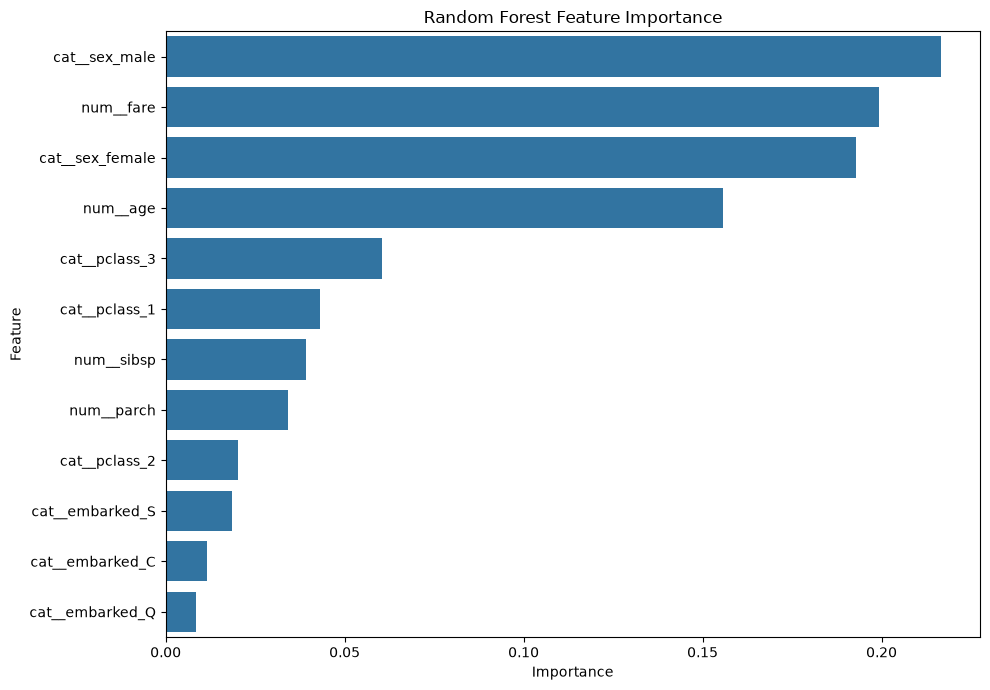

In [56]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 10.1 Feature Importance Findings

Random Forest feature importance analysis revealed:

1. Gender-related features were among the most influential.
2. Ticket fare was the second most important individual feature.
3. Passenger age contributed significantly to predictions.
4. Passenger class also provided useful predictive information.
5. Embarkation port had relatively low individual importance.

These findings broadly align with the exploratory data analysis.

Feature importance represents model-specific predictive contribution
and does not establish causal relationships.

In [57]:
final_model = lr_search.best_estimator_

print("Final Model:")
print(final_model)

Final Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'sibsp', 'parch',
                                                   'fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unkno

In [58]:
final_predictions = final_model.predict(X_test)

print("Final Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Final Classification Report:\n")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Not Survived", "Survived"]
    )
)

Final Accuracy: 0.8100558659217877
Final Classification Report:

              precision    recall  f1-score   support

Not Survived       0.86      0.83      0.84       110
    Survived       0.74      0.78      0.76        69

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [59]:
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save complete pipeline
joblib.dump(
    final_model,
    "../models/titanic_survival_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
